In [1]:
# MLP: Multi Layer Perceptron （多層ニューラルネットワーク）
# 入力層＋隠れ層＋出力層
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # matplotlibベースのグラフ描画ライブラリで、ヒートマップなどを容易に描画可能
from torchvision import datasets, transforms # データセットと前処理用パッケージ
from torch.utils.data import DataLoader # データセットをミニバッチに分けて順に取り出す

In [2]:
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() # Mac用のGPU
    else "cpu"
)
device

'mps'

In [3]:
# 前処理
transform = transforms.Compose([
    # 画像の Tensor クラスへの変換
    # チャネルラスト形式から、チャネルファースト形式に変換
    # 0~255の整数値を、0~１の浮動小数点に変換
    transforms.ToTensor() 
])

# ./data に MNIST データがダウンロードされる
# transform はデータを取り出すときに変換してねという意味（ダウンロード段階は関係ない）
train_dataset = datasets.MNIST(
    root="./data",
    download=True,
    train=True,
    transform=transform
)

In [4]:
num_batches = 100 # ミニバッチのバッチ数

train_dataloader = DataLoader(
    train_dataset,
    batch_size=num_batches,
    shuffle=True
)

In [5]:
train_iter = iter(train_dataloader)
imgs, labels = next(train_iter) # 最初のバッチを取り出す
print(imgs.size()) # (B, C, H, W) バッチ数、チャネル数、高さ、幅
print(labels) # 教師データが1次元で入っている

torch.Size([100, 1, 28, 28])
tensor([4, 3, 7, 2, 6, 4, 8, 1, 0, 4, 2, 3, 4, 8, 0, 4, 9, 8, 2, 1, 7, 6, 5, 1,
        3, 4, 3, 5, 5, 3, 4, 0, 0, 1, 0, 3, 6, 6, 3, 3, 8, 1, 2, 1, 4, 7, 3, 7,
        5, 9, 8, 9, 7, 0, 6, 1, 4, 3, 9, 4, 3, 6, 5, 9, 8, 7, 0, 1, 4, 6, 2, 6,
        5, 9, 8, 3, 7, 2, 1, 1, 9, 3, 4, 0, 4, 8, 3, 3, 2, 3, 9, 7, 0, 8, 8, 5,
        3, 5, 6, 6])


tensor(4)


<Axes: >

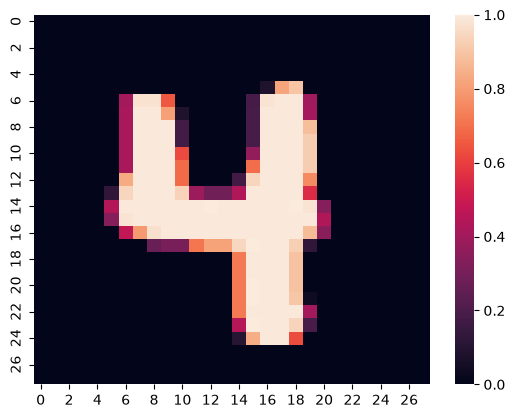

In [6]:
print(labels[0])

img = imgs[0]
img_permute = img.permute(1, 2, 0) # チャネルファーストからチャネルラストへ変換
sns.heatmap(img_permute.numpy()[:, :, 0]) # チャネルの次元を落とす

In [7]:
# モデルの作成
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Linear(28 * 28, 400),
            nn.ReLU(inplace=True), # inplace は ReLU 実行後に、元の配列を置き換える（メモリ節約）
            nn.Linear(400, 200),
            nn.ReLU(inplace=True),
            nn.Linear(200, 100),
            nn.ReLU(inplace=True),
            nn.Linear(100, 10)
        )

    def forward(self, x):
        output = self.classifier(x)
        return output

In [8]:
model = MLP()
model.to(device) # GPUで実行できるように設定する

MLP(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=400, out_features=200, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): Linear(in_features=100, out_features=10, bias=True)
  )
)

In [9]:
criterion = nn.CrossEntropyLoss() # 損失関数（クロスエントロピー損失）
optimizer = optim.Adam(model.parameters(), lr=0.001) 

In [10]:
num_epochs = 15
losses = []
accs = []
for epoch in range(num_epochs):
    running_loss = 0.0
    running_acc = 0.0
    
    # ミニバッチのループを作成する
    # 順伝播→損失計算→逆伝播→重み・バイアス更新のループ
    for imgs, labels in train_dataloader:
        imgs = imgs.view(num_batches, -1)
        imgs = imgs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        output = model(imgs)
        loss = criterion(output, labels)
        running_loss += loss.item()
        pred = torch.argmax(output, dim=1) # dim=1は、最大のラベルを抜き出すという意味
        running_acc += torch.mean(pred.eq(labels).float()).item()
        loss.backward()
        optimizer.step()
    running_loss /= len(train_dataloader)
    running_acc /= len(train_dataloader)
    losses.append(running_loss)
    accs.append(running_acc)
    print("epoch: {}, loss: {}, acc: {}".format(epoch, running_loss, running_acc))

epoch: 0, loss: 0.30793644811337195, acc: 0.9070166679223378
epoch: 1, loss: 0.10966927183947216, acc: 0.9670833396911621
epoch: 2, loss: 0.07328160472214222, acc: 0.9769166759649912
epoch: 3, loss: 0.05107936285746594, acc: 0.9833333440621694
epoch: 4, loss: 0.0398861033077507, acc: 0.9875000091393789
epoch: 5, loss: 0.029465326047502457, acc: 0.9907500078280767
epoch: 6, loss: 0.02638027365494054, acc: 0.9912833411494891
epoch: 7, loss: 0.02145280697843797, acc: 0.9928833396236102
epoch: 8, loss: 0.017945919143458014, acc: 0.99405000547568
epoch: 9, loss: 0.017904796294945603, acc: 0.9939666722218196
epoch: 10, loss: 0.01559726513849455, acc: 0.9948166712125143
epoch: 11, loss: 0.013993840728429253, acc: 0.9954666708906491
epoch: 12, loss: 0.009573450136461664, acc: 0.997216669122378
epoch: 13, loss: 0.013551667687312753, acc: 0.9956833374500275
epoch: 14, loss: 0.013539248715327024, acc: 0.9955666706959406


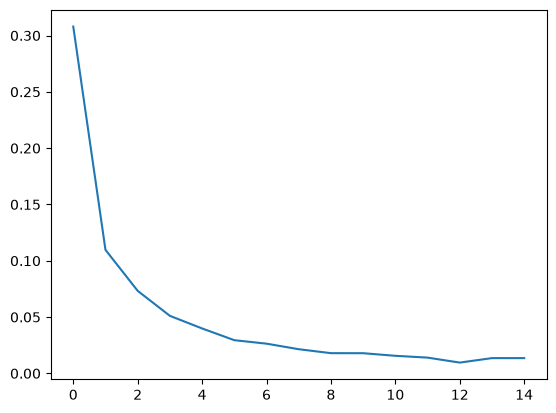

In [11]:
plt.plot(losses)

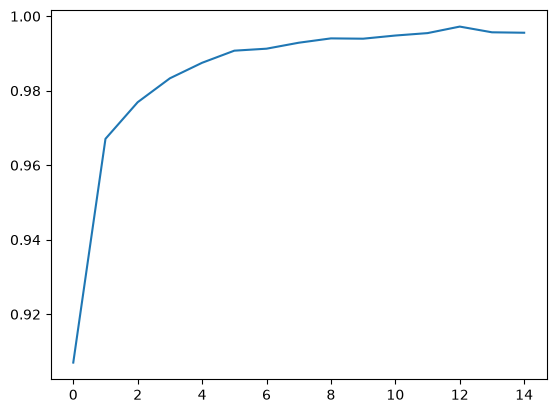

In [12]:
plt.plot(accs)

In [13]:
train_iter = iter(train_dataloader)
imgs, labels = next(train_iter)
print(labels)

imgs_gpu = imgs.view(100, -1).to(device)
output = model(imgs_gpu)
pred = torch.argmax(output, dim=1)
print(pred)

tensor([5, 2, 6, 9, 1, 6, 4, 1, 1, 5, 1, 0, 1, 8, 1, 2, 7, 9, 3, 4, 7, 7, 5, 5,
        2, 8, 7, 4, 6, 7, 4, 7, 7, 9, 7, 5, 8, 1, 6, 6, 1, 4, 5, 9, 5, 2, 8, 3,
        8, 3, 6, 2, 7, 7, 1, 3, 6, 0, 4, 5, 2, 5, 9, 3, 0, 8, 4, 2, 0, 3, 3, 9,
        0, 0, 3, 0, 1, 7, 7, 6, 8, 0, 9, 8, 4, 6, 0, 3, 2, 1, 9, 2, 3, 3, 5, 8,
        6, 0, 8, 1])
tensor([5, 2, 6, 9, 1, 6, 4, 1, 1, 5, 1, 0, 1, 8, 1, 2, 2, 9, 3, 4, 7, 7, 5, 5,
        2, 8, 7, 4, 6, 7, 4, 7, 7, 9, 7, 5, 8, 1, 6, 6, 1, 4, 5, 9, 5, 2, 8, 3,
        8, 3, 6, 2, 7, 7, 1, 3, 6, 0, 4, 5, 2, 5, 9, 3, 0, 8, 4, 2, 0, 3, 3, 9,
        0, 0, 3, 0, 1, 7, 7, 6, 8, 0, 9, 8, 4, 6, 0, 3, 2, 1, 9, 2, 3, 3, 5, 8,
        6, 0, 8, 1], device='mps:0')


In [14]:
# モデルの保存
params = model.state_dict() # モデルの情報を抜き出す
torch.save(params, "model.prm")
!ls # model.prm というファイルの存在を確認できる

data                           requirements.txt
Makefile                       s21-linear-regression.ipynb
model.prm                      s22-mnist-classification.ipynb


In [15]:
# 保存したモデルの読み込み
param_load = torch.load("model.prm")
model.load_state_dict(param_load)

<All keys matched successfully>